In [ ]:
"""
Tekthib RL Training Analysis Notebook
======================================

This notebook provides comprehensive visualization and analysis of your
parallel RL training results.

Usage:
    1. Place this file in the same directory as your training stats JSON
    2. Update the JSON_PATH variable below
    3. Run all cells
"""

# ============================================================================
# IMPORTS AND SETUP
# ============================================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
from scipy.ndimage import gaussian_filter1d
from typing import Dict, List

# Set style for better-looking plots
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# ============================================================================
# CONFIGURATION
# ============================================================================

# Update this path to your JSON file
JSON_PATH = 'rl_checkpoints_parallel/parallel_training_stats.json'

# Smoothing parameters
SMOOTHING_WINDOW = 20  # For moving averages
GAUSSIAN_SIGMA = 3     # For Gaussian smoothing


In [12]:

# ============================================================================
# DATA LOADING
# ============================================================================

def load_training_data(json_path: str) -> tuple:
    """Load and parse training data from JSON file."""
    with open(json_path, 'r') as f:
        data = json.load(f)
    
    # Convert to DataFrame for easier analysis
    df = pd.DataFrame(data['episodes'])
    
    # Parse timestamps
    df['timestamp'] = pd.to_datetime(df['timestamp'])
    df['time_elapsed'] = (df['timestamp'] - df['timestamp'].iloc[0]).dt.total_seconds()
    
    # Add cumulative metrics
    df['cumulative_wins'] = (df['placement'] == 1).cumsum()
    df['cumulative_losses'] = (df['placement'] != 1).cumsum()
    
    return df, data

print("Loading training data...")
df, summary = load_training_data(JSON_PATH)
print(f"✓ Loaded {len(df)} episodes")
print(f"✓ Training time: {summary['total_training_time']/3600:.2f} hours")
print(f"✓ Win rate: {summary['overall_win_rate']*100:.1f}%")
print()

Loading training data...
✓ Loaded 670 episodes
✓ Training time: 0.66 hours
✓ Win rate: 41.2%



In [9]:
train_time_per_episode = summary['total_training_time'] / len(df) / 60
print('expected training time:', train_time_per_episode * 2000, 'minutes for 2000 episodes')

expected training time: 109.8398275764621 minutes for 2000 episodes


TRAINING SUMMARY STATISTICS

📊 Overall Performance:
   Total Episodes:        670
   Total Wins:            276 (41.2%)
   Total Losses:          394
   Avg Placement:         2.58
   Training Updates:      112
   Training Time:         0.66 hours

⚡ Speed Metrics:
   Episodes/Hour:         1034.3
   Avg Episode Time:      142.2s
   Min Episode Time:      32.1s
   Max Episode Time:      449.7s

📈 Learning Progress:
   First 100 episodes:
      Win Rate:           48.0%
      Avg Placement:      2.25
   Last 100 episodes:
      Win Rate:           31.0%
      Avg Placement:      2.84
   Improvement:
      Win Rate Change:    -17.0%
      Placement Change:   +0.59

👥 Worker Statistics:
   Total Workers:         53
   Avg Episodes/Worker:   12.6
   Most Active Worker:    Worker 5 (19 episodes)
   Best Performing:       Worker 44 (100.0% WR)

🎲 Exploration Progress:
   Starting Epsilon:      1.000
   Current Epsilon:       1.000
   Decay Progress:        0.0%


Generating win rate analysis

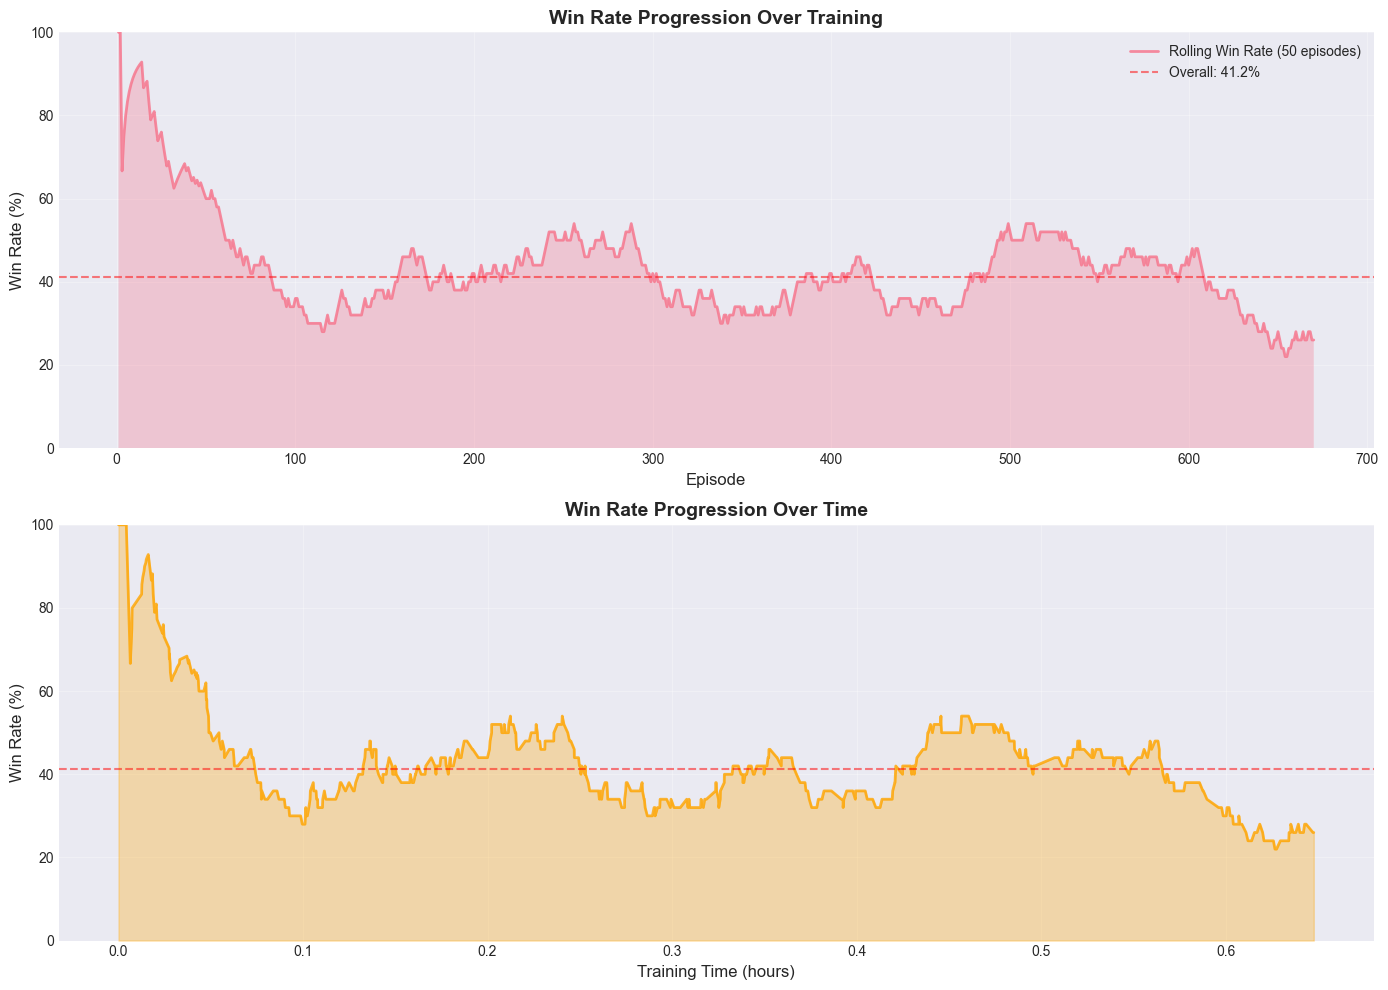

Generating placement analysis...


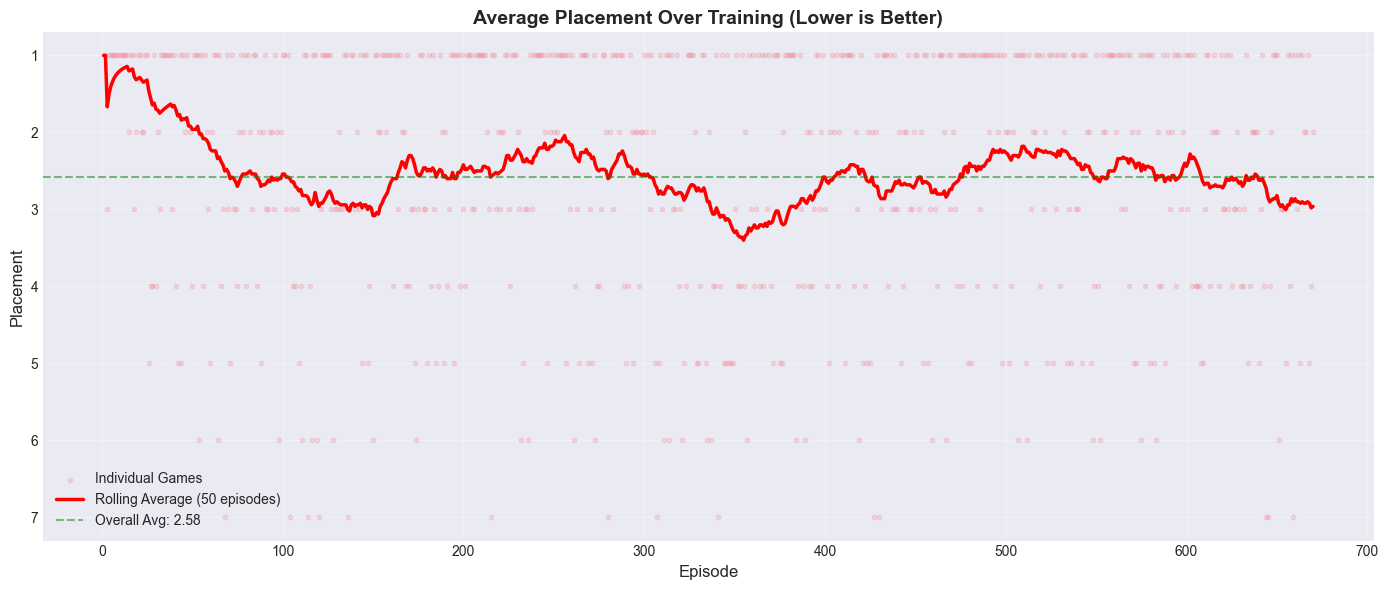

Generating reward analysis...


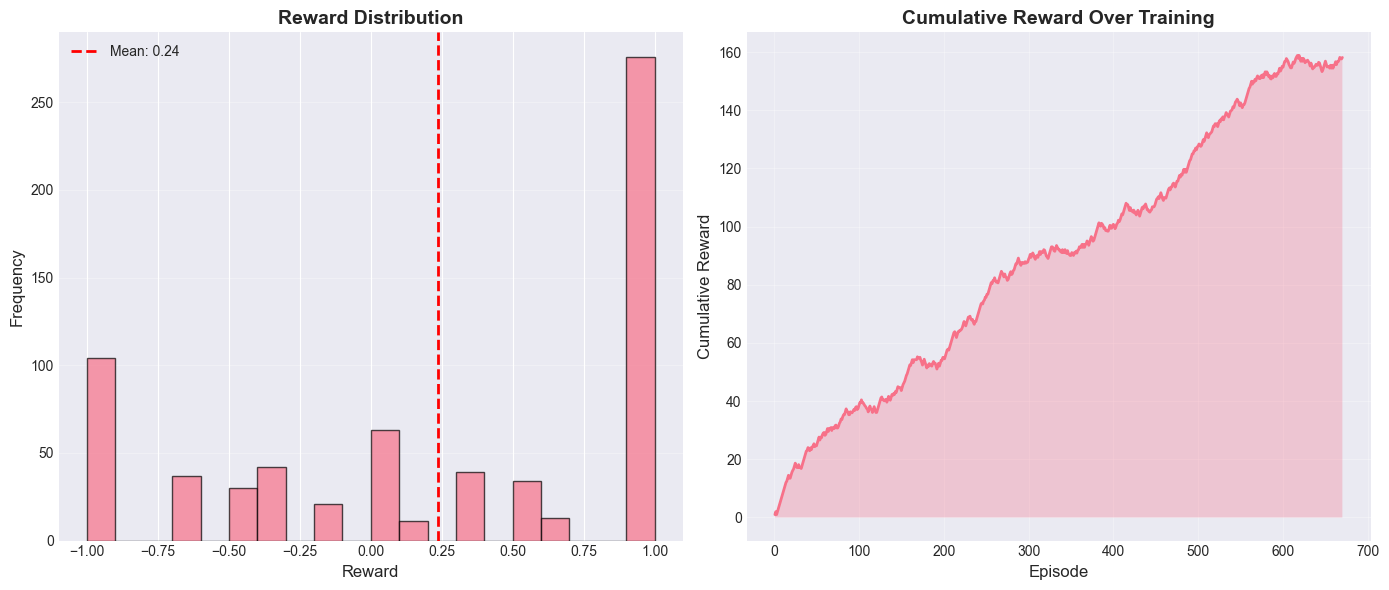

Generating epsilon decay analysis...


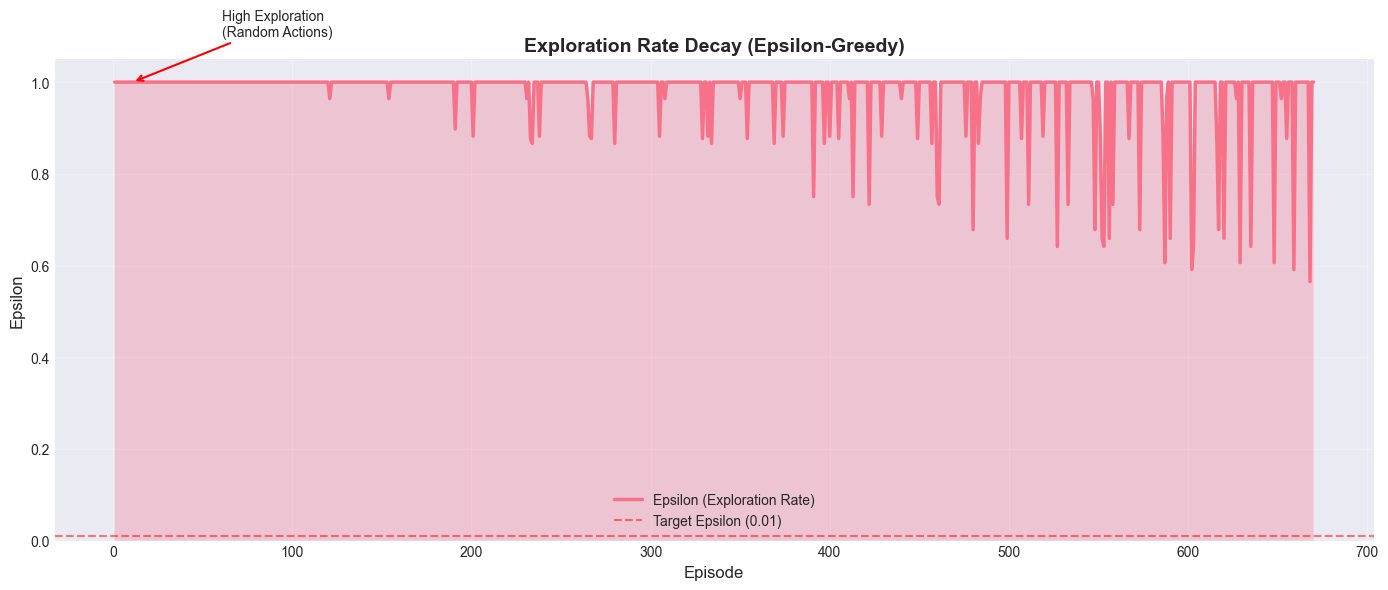

Generating episode duration analysis...


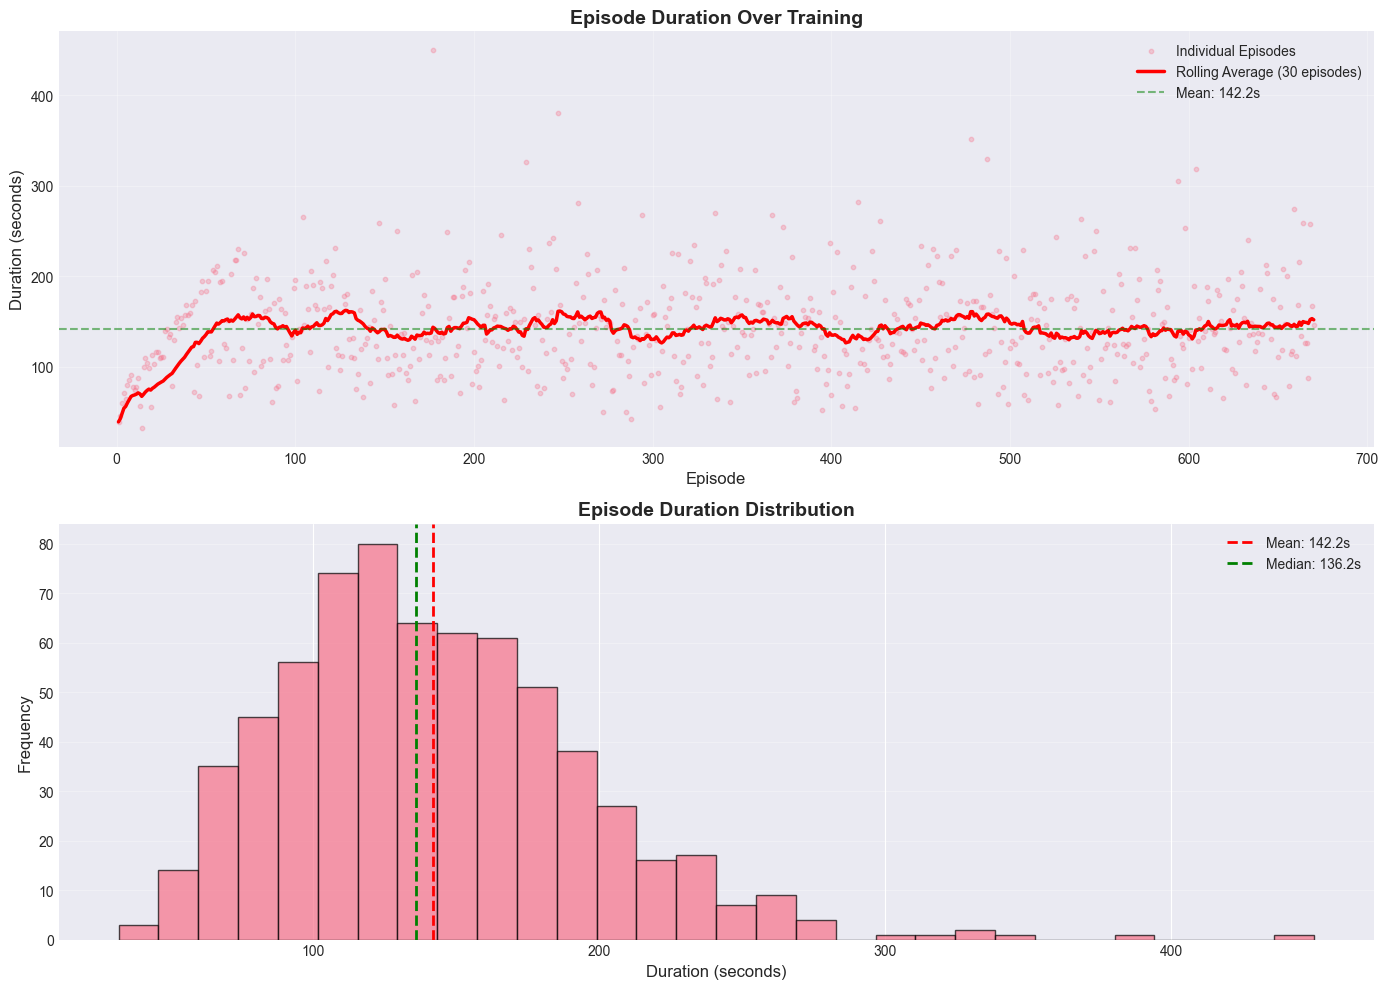

Generating worker performance analysis...


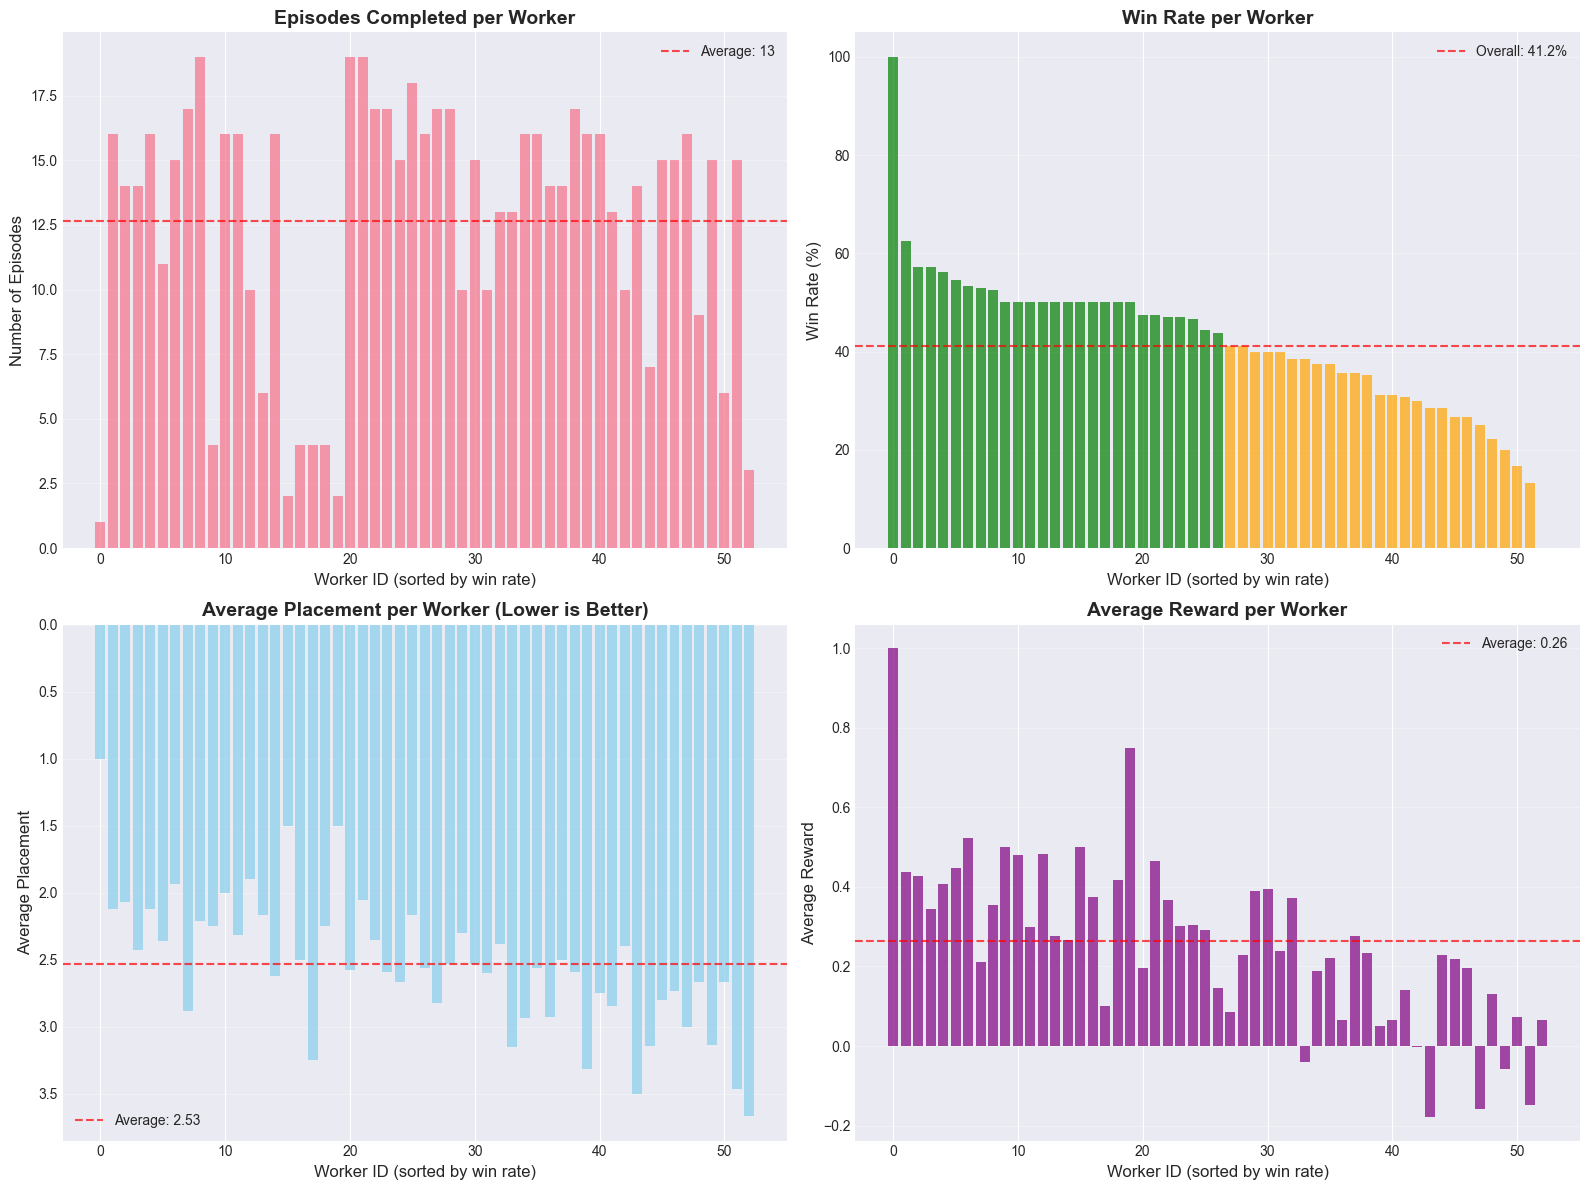


🏆 Top 5 Performing Workers:
           episodes  win_rate  avg_placement
worker_id                                   
44                1  1.000000       1.000000
21               16  0.625000       2.125000
12               14  0.571429       2.071429
22               14  0.571429       2.428571
49               16  0.562500       2.125000

⚠️  Bottom 5 Performing Workers:
           episodes  win_rate  avg_placement
worker_id                                   
41                9  0.222222       2.666667
24               15  0.200000       3.133333
27                6  0.166667       2.666667
26               15  0.133333       3.466667
50                3  0.000000       3.666667

Generating training speed analysis...


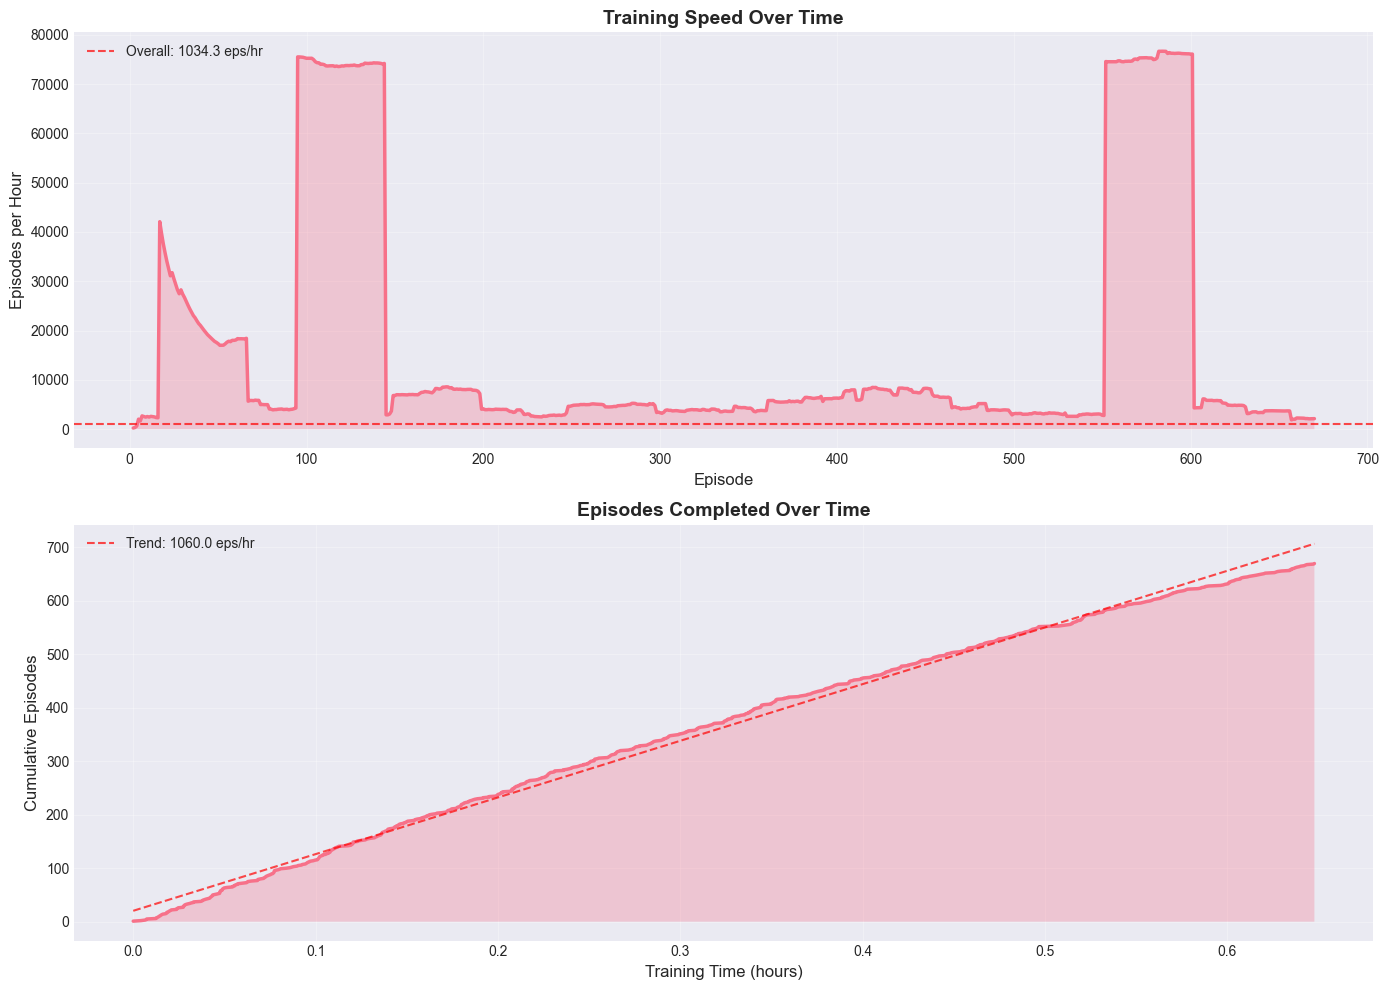

Generating placement distribution analysis...


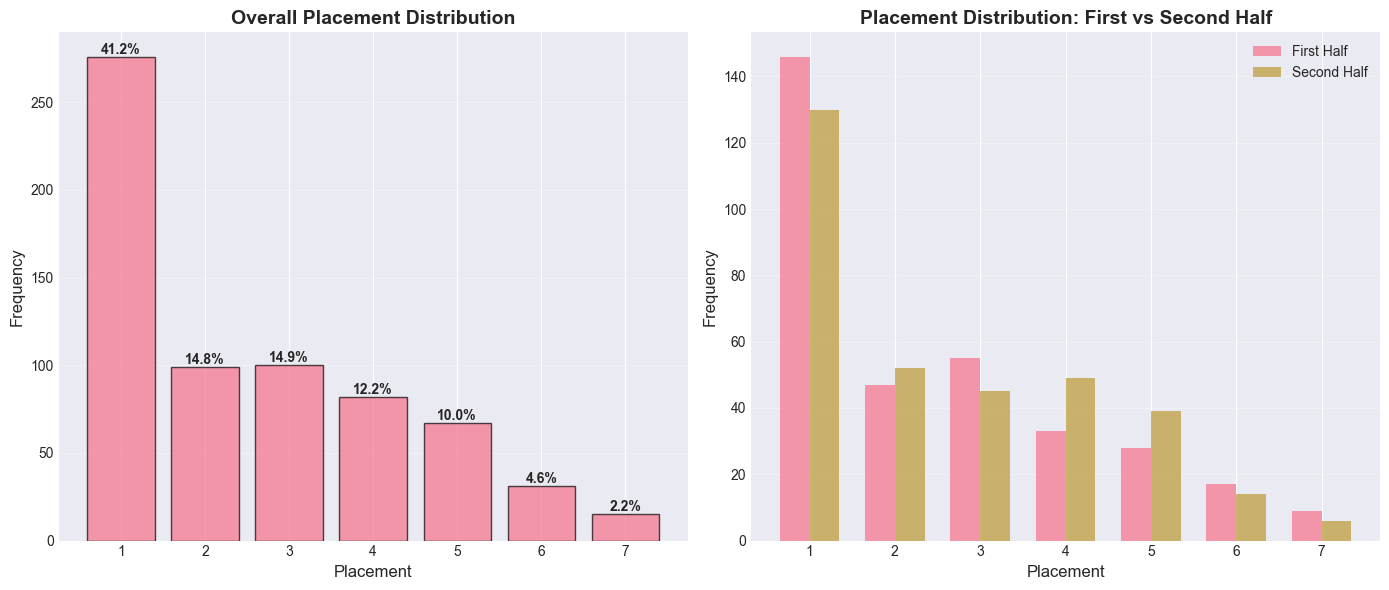

Generating learning curve...


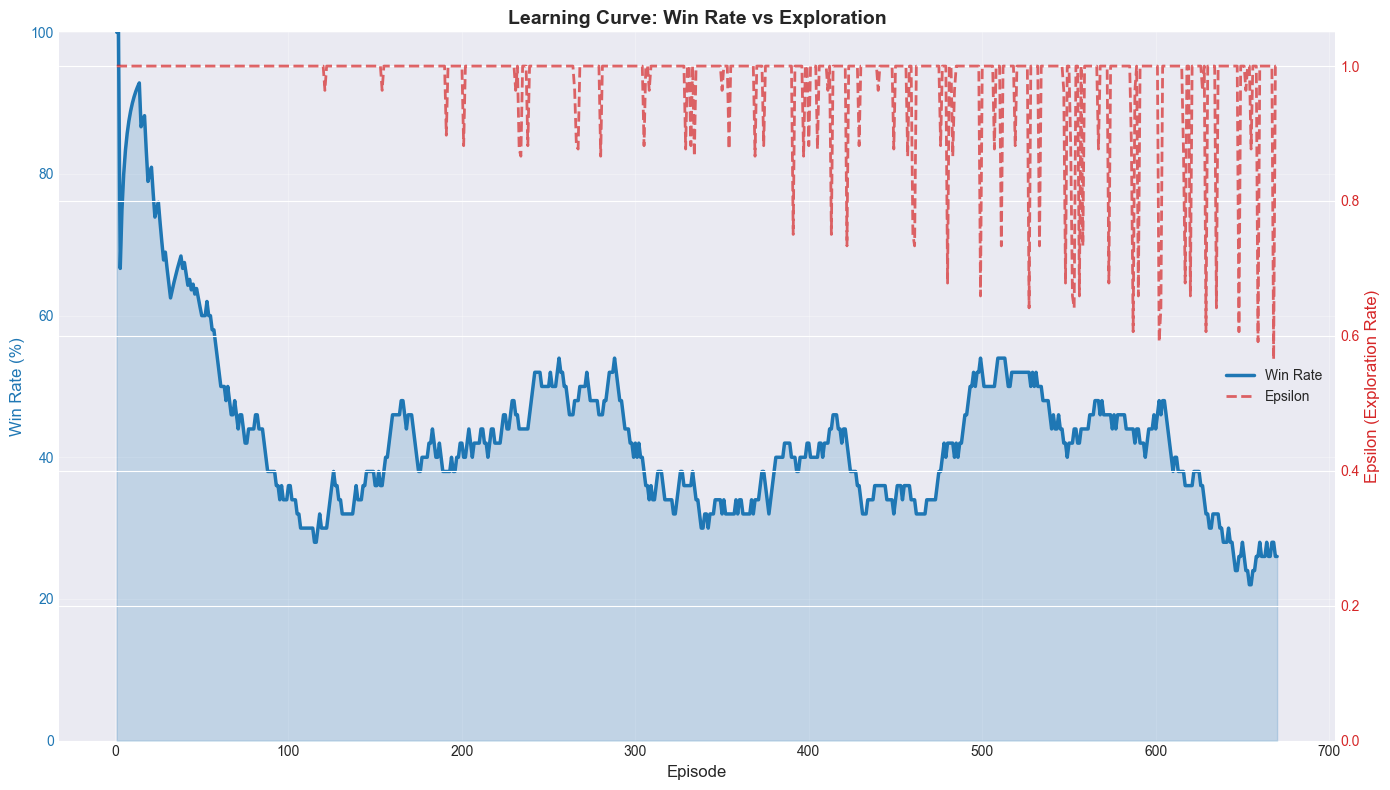

In [ ]:



# ============================================================================
# SUMMARY STATISTICS
# ============================================================================

def print_summary_stats(df: pd.DataFrame, summary: Dict):
    """Print comprehensive summary statistics."""
    print("="*80)
    print("TRAINING SUMMARY STATISTICS")
    print("="*80)
    print()
    
    # Overall metrics
    print("📊 Overall Performance:")
    print(f"   Total Episodes:        {len(df)}")
    print(f"   Total Wins:            {summary['total_wins']} ({summary['overall_win_rate']*100:.1f}%)")
    print(f"   Total Losses:          {summary['total_losses']}")
    print(f"   Avg Placement:         {summary['overall_avg_placement']:.2f}")
    print(f"   Training Updates:      {summary['total_training_updates']}")
    print(f"   Training Time:         {summary['total_training_time']/3600:.2f} hours")
    print()
    
    # Speed metrics
    total_seconds = df['time_elapsed'].iloc[-1]
    eps_per_hour = len(df) / (total_seconds / 3600)
    avg_episode_time = df['episode_time'].mean()
    
    print("⚡ Speed Metrics:")
    print(f"   Episodes/Hour:         {eps_per_hour:.1f}")
    print(f"   Avg Episode Time:      {avg_episode_time:.1f}s")
    print(f"   Min Episode Time:      {df['episode_time'].min():.1f}s")
    print(f"   Max Episode Time:      {df['episode_time'].max():.1f}s")
    print()
    
    # Learning progress
    first_100 = df.head(100)
    last_100 = df.tail(100)
    
    print("📈 Learning Progress:")
    print(f"   First 100 episodes:")
    print(f"      Win Rate:           {(first_100['placement'] == 1).mean()*100:.1f}%")
    print(f"      Avg Placement:      {first_100['placement'].mean():.2f}")
    print(f"   Last 100 episodes:")
    print(f"      Win Rate:           {(last_100['placement'] == 1).mean()*100:.1f}%")
    print(f"      Avg Placement:      {last_100['placement'].mean():.2f}")
    print(f"   Improvement:")
    print(f"      Win Rate Change:    {((last_100['placement'] == 1).mean() - (first_100['placement'] == 1).mean())*100:+.1f}%")
    print(f"      Placement Change:   {(last_100['placement'].mean() - first_100['placement'].mean()):+.2f}")
    print()
    
    # Worker statistics
    print("👥 Worker Statistics:")
    worker_stats = df.groupby('worker_id').agg({
        'episode': 'count',
        'placement': lambda x: (x == 1).mean()
    }).rename(columns={'episode': 'episodes', 'placement': 'win_rate'})
    
    print(f"   Total Workers:         {df['worker_id'].nunique()}")
    print(f"   Avg Episodes/Worker:   {worker_stats['episodes'].mean():.1f}")
    print(f"   Most Active Worker:    Worker {worker_stats['episodes'].idxmax()} ({worker_stats['episodes'].max()} episodes)")
    print(f"   Best Performing:       Worker {worker_stats['win_rate'].idxmax()} ({worker_stats['win_rate'].max()*100:.1f}% WR)")
    print()
    
    # Epsilon decay
    print("🎲 Exploration Progress:")
    print(f"   Starting Epsilon:      {df['epsilon'].iloc[0]:.3f}")
    print(f"   Current Epsilon:       {df['epsilon'].iloc[-1]:.3f}")
    print(f"   Decay Progress:        {(1 - df['epsilon'].iloc[-1]/(df['epsilon'].iloc[0] or 1))*100:.1f}%")
    print()
    
    print("="*80)
    print()

print_summary_stats(df, summary)

# ============================================================================
# VISUALIZATION FUNCTIONS
# ============================================================================

def smooth_data(data: np.ndarray, method: str = 'moving_avg') -> np.ndarray:
    """Apply smoothing to data for clearer trends."""
    if method == 'moving_avg':
        return pd.Series(data).rolling(window=SMOOTHING_WINDOW, min_periods=1).mean().values
    elif method == 'gaussian':
        return gaussian_filter1d(data, sigma=GAUSSIAN_SIGMA)
    return data

# ============================================================================
# PLOT 1: Win Rate Over Time
# ============================================================================

def plot_win_rate(df: pd.DataFrame):
    """Plot win rate progression over time."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
    
    # Calculate rolling win rate
    window = 50
    df['rolling_win_rate'] = (df['placement'] == 1).rolling(window=window, min_periods=1).mean() * 100
    
    # Plot 1: Win rate by episode
    ax1.plot(df['episode'], df['rolling_win_rate'], 
             label=f'Rolling Win Rate ({window} episodes)', linewidth=2, alpha=0.8)
    ax1.axhline(y=df['win_rate'].iloc[-1]*100, color='red', linestyle='--', 
                label=f'Overall: {df["win_rate"].iloc[-1]*100:.1f}%', alpha=0.5)
    ax1.fill_between(df['episode'], 0, df['rolling_win_rate'], alpha=0.3)
    
    ax1.set_xlabel('Episode', fontsize=12)
    ax1.set_ylabel('Win Rate (%)', fontsize=12)
    ax1.set_title('Win Rate Progression Over Training', fontsize=14, fontweight='bold')
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 100)
    
    # Plot 2: Win rate by time
    ax2.plot(df['time_elapsed']/3600, df['rolling_win_rate'], 
             linewidth=2, alpha=0.8, color='orange')
    ax2.axhline(y=df['win_rate'].iloc[-1]*100, color='red', linestyle='--', alpha=0.5)
    ax2.fill_between(df['time_elapsed']/3600, 0, df['rolling_win_rate'], alpha=0.3, color='orange')
    
    ax2.set_xlabel('Training Time (hours)', fontsize=12)
    ax2.set_ylabel('Win Rate (%)', fontsize=12)
    ax2.set_title('Win Rate Progression Over Time', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    ax2.set_ylim(0, 100)
    
    plt.tight_layout()
    plt.show()

print("Generating win rate analysis...")
plot_win_rate(df)

# ============================================================================
# PLOT 2: Average Placement Over Time
# ============================================================================

def plot_placement(df: pd.DataFrame):
    """Plot average placement progression."""
    fig, ax = plt.subplots(figsize=(14, 6))
    
    # Calculate rolling average placement
    window = 50
    df['rolling_placement'] = df['placement'].rolling(window=window, min_periods=1).mean()
    
    # Plot raw and smoothed data
    ax.scatter(df['episode'], df['placement'], alpha=0.2, s=10, label='Individual Games')
    ax.plot(df['episode'], df['rolling_placement'], 
            label=f'Rolling Average ({window} episodes)', linewidth=2.5, color='red')
    ax.axhline(y=df['avg_placement_all'].iloc[-1], color='green', linestyle='--', 
               label=f'Overall Avg: {df["avg_placement_all"].iloc[-1]:.2f}', alpha=0.5)
    
    ax.set_xlabel('Episode', fontsize=12)
    ax.set_ylabel('Placement', fontsize=12)
    ax.set_title('Average Placement Over Training (Lower is Better)', fontsize=14, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    ax.invert_yaxis()  # Lower placement is better
    
    plt.tight_layout()
    plt.show()

print("Generating placement analysis...")
plot_placement(df)

# ============================================================================
# PLOT 3: Reward Distribution
# ============================================================================

def plot_rewards(df: pd.DataFrame):
    """Plot reward distribution and progression."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot 1: Reward distribution
    ax1.hist(df['reward'], bins=20, edgecolor='black', alpha=0.7)
    ax1.axvline(df['reward'].mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Mean: {df["reward"].mean():.2f}')
    ax1.set_xlabel('Reward', fontsize=12)
    ax1.set_ylabel('Frequency', fontsize=12)
    ax1.set_title('Reward Distribution', fontsize=14, fontweight='bold')
    ax1.legend()
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Plot 2: Cumulative reward over time
    df['cumulative_reward'] = df['reward'].cumsum()
    ax2.plot(df['episode'], df['cumulative_reward'], linewidth=2)
    ax2.fill_between(df['episode'], 0, df['cumulative_reward'], alpha=0.3)
    ax2.set_xlabel('Episode', fontsize=12)
    ax2.set_ylabel('Cumulative Reward', fontsize=12)
    ax2.set_title('Cumulative Reward Over Training', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

print("Generating reward analysis...")
plot_rewards(df)

# ============================================================================
# PLOT 4: Epsilon Decay
# ============================================================================

def plot_epsilon(df: pd.DataFrame):
    """Plot epsilon (exploration rate) decay over time."""
    fig, ax = plt.subplots(figsize=(14, 6))
    
    ax.plot(df['episode'], df['epsilon'], linewidth=2.5, label='Epsilon (Exploration Rate)')
    ax.fill_between(df['episode'], 0, df['epsilon'], alpha=0.3)
    ax.axhline(y=0.01, color='red', linestyle='--', 
               label='Target Epsilon (0.01)', alpha=0.5)
    
    ax.set_xlabel('Episode', fontsize=12)
    ax.set_ylabel('Epsilon', fontsize=12)
    ax.set_title('Exploration Rate Decay (Epsilon-Greedy)', fontsize=14, fontweight='bold')
    ax.legend(loc='best')
    ax.grid(True, alpha=0.3)
    ax.set_ylim(0, 1.05)
    
    # Add annotations
    mid_point = len(df) // 2
    ax.annotate('High Exploration\n(Random Actions)', 
                xy=(df['episode'].iloc[10], df['epsilon'].iloc[10]),
                xytext=(df['episode'].iloc[10] + 50, df['epsilon'].iloc[10] + 0.1),
                arrowprops=dict(arrowstyle='->', color='red', lw=1.5),
                fontsize=10, ha='left')
    
    if df['epsilon'].iloc[-1] < 0.5:
        ax.annotate('Low Exploration\n(Learned Policy)', 
                    xy=(df['episode'].iloc[-1], df['epsilon'].iloc[-1]),
                    xytext=(df['episode'].iloc[-1] - 100, df['epsilon'].iloc[-1] + 0.15),
                    arrowprops=dict(arrowstyle='->', color='green', lw=1.5),
                    fontsize=10, ha='right')
    
    plt.tight_layout()
    plt.show()

print("Generating epsilon decay analysis...")
plot_epsilon(df)

# ============================================================================
# PLOT 5: Episode Duration Analysis
# ============================================================================

def plot_episode_duration(df: pd.DataFrame):
    """Plot episode duration statistics."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
    
    # Plot 1: Episode duration over time
    window = 30
    df['rolling_duration'] = df['episode_time'].rolling(window=window, min_periods=1).mean()
    
    ax1.scatter(df['episode'], df['episode_time'], alpha=0.3, s=10, label='Individual Episodes')
    ax1.plot(df['episode'], df['rolling_duration'], 
             label=f'Rolling Average ({window} episodes)', linewidth=2.5, color='red')
    ax1.axhline(y=df['episode_time'].mean(), color='green', linestyle='--', 
                label=f'Mean: {df["episode_time"].mean():.1f}s', alpha=0.5)
    
    ax1.set_xlabel('Episode', fontsize=12)
    ax1.set_ylabel('Duration (seconds)', fontsize=12)
    ax1.set_title('Episode Duration Over Training', fontsize=14, fontweight='bold')
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Duration distribution
    ax2.hist(df['episode_time'], bins=30, edgecolor='black', alpha=0.7)
    ax2.axvline(df['episode_time'].mean(), color='red', linestyle='--', 
                linewidth=2, label=f'Mean: {df["episode_time"].mean():.1f}s')
    ax2.axvline(df['episode_time'].median(), color='green', linestyle='--', 
                linewidth=2, label=f'Median: {df["episode_time"].median():.1f}s')
    ax2.set_xlabel('Duration (seconds)', fontsize=12)
    ax2.set_ylabel('Frequency', fontsize=12)
    ax2.set_title('Episode Duration Distribution', fontsize=14, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()

print("Generating episode duration analysis...")
plot_episode_duration(df)

# ============================================================================
# PLOT 6: Worker Performance Comparison
# ============================================================================

def plot_worker_performance(df: pd.DataFrame):
    """Compare performance across different workers."""
    fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(16, 12))
    
    # Aggregate worker statistics
    worker_stats = df.groupby('worker_id').agg({
        'episode': 'count',
        'placement': ['mean', lambda x: (x == 1).mean()],
        'reward': 'mean',
        'episode_time': 'mean'
    })
    worker_stats.columns = ['episodes', 'avg_placement', 'win_rate', 'avg_reward', 'avg_time']
    worker_stats = worker_stats.sort_values('win_rate', ascending=False)
    
    # Plot 1: Episodes per worker
    ax1.bar(range(len(worker_stats)), worker_stats['episodes'], alpha=0.7)
    ax1.set_xlabel('Worker ID (sorted by win rate)', fontsize=12)
    ax1.set_ylabel('Number of Episodes', fontsize=12)
    ax1.set_title('Episodes Completed per Worker', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    ax1.axhline(y=worker_stats['episodes'].mean(), color='red', linestyle='--', 
                label=f'Average: {worker_stats["episodes"].mean():.0f}', alpha=0.7)
    ax1.legend()
    
    # Plot 2: Win rate per worker
    colors = ['green' if wr > df['win_rate'].iloc[-1] else 'orange' 
              for wr in worker_stats['win_rate']]
    ax2.bar(range(len(worker_stats)), worker_stats['win_rate']*100, color=colors, alpha=0.7)
    ax2.set_xlabel('Worker ID (sorted by win rate)', fontsize=12)
    ax2.set_ylabel('Win Rate (%)', fontsize=12)
    ax2.set_title('Win Rate per Worker', fontsize=14, fontweight='bold')
    ax2.grid(True, alpha=0.3, axis='y')
    ax2.axhline(y=df['win_rate'].iloc[-1]*100, color='red', linestyle='--', 
                label=f'Overall: {df["win_rate"].iloc[-1]*100:.1f}%', alpha=0.7)
    ax2.legend()
    
    # Plot 3: Average placement per worker
    ax3.bar(range(len(worker_stats)), worker_stats['avg_placement'], alpha=0.7, color='skyblue')
    ax3.set_xlabel('Worker ID (sorted by win rate)', fontsize=12)
    ax3.set_ylabel('Average Placement', fontsize=12)
    ax3.set_title('Average Placement per Worker (Lower is Better)', fontsize=14, fontweight='bold')
    ax3.grid(True, alpha=0.3, axis='y')
    ax3.axhline(y=worker_stats['avg_placement'].mean(), color='red', linestyle='--', 
                label=f'Average: {worker_stats["avg_placement"].mean():.2f}', alpha=0.7)
    ax3.legend()
    ax3.invert_yaxis()
    
    # Plot 4: Average reward per worker
    ax4.bar(range(len(worker_stats)), worker_stats['avg_reward'], alpha=0.7, color='purple')
    ax4.set_xlabel('Worker ID (sorted by win rate)', fontsize=12)
    ax4.set_ylabel('Average Reward', fontsize=12)
    ax4.set_title('Average Reward per Worker', fontsize=14, fontweight='bold')
    ax4.grid(True, alpha=0.3, axis='y')
    ax4.axhline(y=worker_stats['avg_reward'].mean(), color='red', linestyle='--', 
                label=f'Average: {worker_stats["avg_reward"].mean():.2f}', alpha=0.7)
    ax4.legend()
    
    plt.tight_layout()
    plt.show()
    
    # Print top/bottom performers
    print("\n🏆 Top 5 Performing Workers:")
    print(worker_stats.head(5)[['episodes', 'win_rate', 'avg_placement']].to_string())
    print("\n⚠️  Bottom 5 Performing Workers:")
    print(worker_stats.tail(5)[['episodes', 'win_rate', 'avg_placement']].to_string())
    print()

print("Generating worker performance analysis...")
plot_worker_performance(df)

# ============================================================================
# PLOT 7: Training Speed Analysis
# ============================================================================

def plot_training_speed(df: pd.DataFrame):
    """Analyze training speed metrics."""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))
    
    # Calculate episodes per hour over time
    window = 50
    df['time_diff'] = df['time_elapsed'].diff()
    df['eps_per_hour'] = 3600 / df['time_diff'].replace(0, np.nan)
    df['rolling_eps_per_hour'] = df['eps_per_hour'].rolling(window=window, min_periods=1).mean()
    
    # Plot 1: Episodes per hour over time
    ax1.plot(df['episode'], df['rolling_eps_per_hour'], linewidth=2.5)
    ax1.fill_between(df['episode'], 0, df['rolling_eps_per_hour'], alpha=0.3)
    overall_speed = len(df) / (df['time_elapsed'].iloc[-1] / 3600)
    ax1.axhline(y=overall_speed, color='red', linestyle='--', 
                label=f'Overall: {overall_speed:.1f} eps/hr', alpha=0.7)
    
    ax1.set_xlabel('Episode', fontsize=12)
    ax1.set_ylabel('Episodes per Hour', fontsize=12)
    ax1.set_title('Training Speed Over Time', fontsize=14, fontweight='bold')
    ax1.legend(loc='best')
    ax1.grid(True, alpha=0.3)
    
    # Plot 2: Cumulative episodes over time
    ax2.plot(df['time_elapsed']/3600, df['episode'], linewidth=2.5)
    ax2.fill_between(df['time_elapsed']/3600, 0, df['episode'], alpha=0.3)
    
    # Add trend line
    z = np.polyfit(df['time_elapsed']/3600, df['episode'], 1)
    p = np.poly1d(z)
    ax2.plot(df['time_elapsed']/3600, p(df['time_elapsed']/3600), 
             "r--", alpha=0.7, label=f'Trend: {z[0]:.1f} eps/hr')
    
    ax2.set_xlabel('Training Time (hours)', fontsize=12)
    ax2.set_ylabel('Cumulative Episodes', fontsize=12)
    ax2.set_title('Episodes Completed Over Time', fontsize=14, fontweight='bold')
    ax2.legend(loc='best')
    ax2.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

print("Generating training speed analysis...")
plot_training_speed(df)

# ============================================================================
# PLOT 8: Placement Distribution
# ============================================================================

def plot_placement_distribution(df: pd.DataFrame):
    """Analyze placement distribution across episodes."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))
    
    # Plot 1: Overall placement distribution
    placement_counts = df['placement'].value_counts().sort_index()
    ax1.bar(placement_counts.index, placement_counts.values, alpha=0.7, edgecolor='black')
    ax1.set_xlabel('Placement', fontsize=12)
    ax1.set_ylabel('Frequency', fontsize=12)
    ax1.set_title('Overall Placement Distribution', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3, axis='y')
    
    # Add percentages
    for i, (place, count) in enumerate(placement_counts.items()):
        percentage = count / len(df) * 100
        ax1.text(place, count, f'{percentage:.1f}%', 
                ha='center', va='bottom', fontweight='bold')
    
    # Plot 2: Placement distribution over time (first vs last half)
    midpoint = len(df) // 2
    first_half = df.head(midpoint)
    second_half = df.tail(midpoint)
    
    x = np.arange(1, df['placement'].max() + 1)
    width = 0.35
    
    first_counts = [len(first_half[first_half['placement'] == i]) for i in x]
    second_counts = [len(second_half[second_half['placement'] == i]) for i in x]
    
    ax2.bar(x - width/2, first_counts, width, label='First Half', alpha=0.7)
    ax2.bar(x + width/2, second_counts, width, label='Second Half', alpha=0.7)
    
    ax2.set_xlabel('Placement', fontsize=12)
    ax2.set_ylabel('Frequency', fontsize=12)
    ax2.set_title('Placement Distribution: First vs Second Half', fontsize=14, fontweight='bold')
    ax2.legend()
    ax2.grid(True, alpha=0.3, axis='y')
    
    plt.tight_layout()
    plt.show()

print("Generating placement distribution analysis...")
plot_placement_distribution(df)

# ============================================================================
# PLOT 9: Learning Curve (Multi-metric)
# ============================================================================

def plot_learning_curve(df: pd.DataFrame):
    """Comprehensive learning curve with multiple metrics."""
    fig, ax1 = plt.subplots(figsize=(14, 8))
    
    # Primary axis: Win rate
    window = 50
    df['rolling_win_rate'] = (df['placement'] == 1).rolling(window=window, min_periods=1).mean() * 100
    
    color1 = 'tab:blue'
    ax1.set_xlabel('Episode', fontsize=12)
    ax1.set_ylabel('Win Rate (%)', color=color1, fontsize=12)
    ax1.plot(df['episode'], df['rolling_win_rate'], color=color1, linewidth=2.5, label='Win Rate')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.fill_between(df['episode'], 0, df['rolling_win_rate'], color=color1, alpha=0.2)
    ax1.set_ylim(0, 100)
    
    # Secondary axis: Epsilon
    ax2 = ax1.twinx()
    color2 = 'tab:red'
    ax2.set_ylabel('Epsilon (Exploration Rate)', color=color2, fontsize=12)
    ax2.plot(df['episode'], df['epsilon'], color=color2, linewidth=2, linestyle='--', label='Epsilon', alpha=0.7)
    ax2.tick_params(axis='y', labelcolor=color2)
    ax2.set_ylim(0, 1.05)
    
    # Title and grid
    ax1.set_title('Learning Curve: Win Rate vs Exploration', fontsize=14, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    
    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')
    
    plt.tight_layout()
    plt.show()

print("Generating learning curve...")
plot_learning_curve(df)

# ============================================================================
# PLOT 10: Heatmap - Performance by Worker and Time
# ============================================================================

def plot_worker_time_heatmap(df: pd.DataFrame):
    """Create heatmap of worker performance over time."""
    # Divide training into time buckets
    num_buckets = 10
    df['time_bucket'] = pd.cut(df['episode'], bins=num_buckets, labels=range(num_buckets))
    
    # Calculate win rate for each worker in each time bucket
    pivot = df.pivot_table(
        values='placement',
        index='worker_id',
        columns='time_bucket',
        aggfunc=lambda x: (x == 1).mean() * 100,
        fill_value=0
    )
    
    # Only show workers with sufficient data
    min_episodes = 5
    worker_episode_counts = df.groupby('worker_id').size()
    